In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Setup completed successfully!")




Setup completed successfully!


In [32]:
ratings = pd.read_csv("data/ratings.csv")
movies = pd.read_csv("data/movies.csv")

print(ratings.head())
print(movies.head())

   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  


In [33]:
num_users = ratings["userId"].nunique()
num_movies = movies["movieId"].nunique()
num_ratings = len(ratings)

total_pairs = num_users * num_movies
sparsity = 1 - (num_ratings / total_pairs)

print("Number of users:", num_users)
print("Number of movies:", num_movies)
print("Number of ratings:", num_ratings)
print("Sparsity:", sparsity)
print("Sparsity percentage:", sparsity * 100, "%")

Number of users: 610
Number of movies: 9742
Number of ratings: 100836
Sparsity: 0.9830317267467884
Sparsity percentage: 98.30317267467883 %


In [34]:
rating_matrix = ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print(rating_matrix.shape)
print(rating_matrix.head())

(610, 9724)
movieId  1       2       3       4       5       6       7       8       \
userId                                                                    
1           4.0     NaN     4.0     NaN     NaN     4.0     NaN     NaN   
2           NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
3           NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
4           NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
5           4.0     NaN     NaN     NaN     NaN     NaN     NaN     NaN   

movieId  9       10      ...  193565  193567  193571  193573  193579  193581  \
userId                   ...                                                   
1           NaN     NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN   
2           NaN     NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN   
3           NaN     NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN   
4           NaN     NaN  ...     NaN     NaN     NaN     NaN  

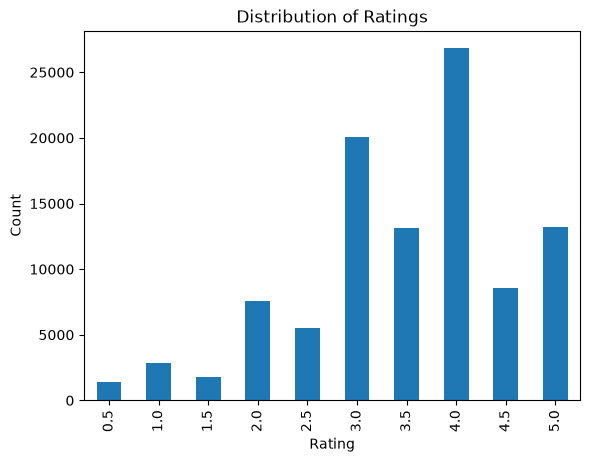

In [35]:
ratings["rating"].value_counts().sort_index().plot(
    kind="bar",
    title="Distribution of Ratings"
)

plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

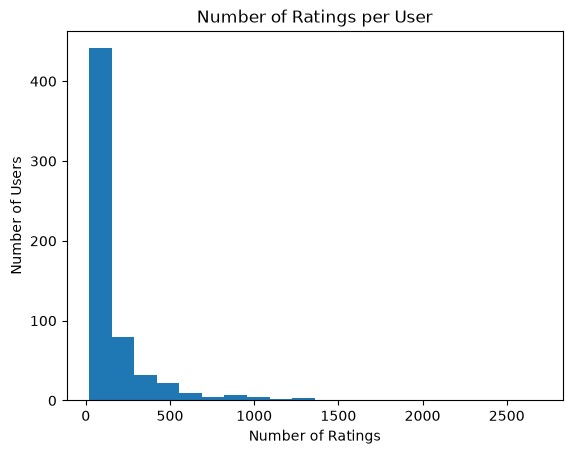

In [36]:
user_rating_counts = ratings.groupby("userId").size()

user_rating_counts.plot(
    kind="hist",
    bins=20,
    title="Number of Ratings per User"
)

plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

In [37]:
print("Mean rating:", ratings["rating"].mean())
print(user_rating_counts.describe())
print("Sparsity %:", sparsity * 100)

Mean rating: 3.501556983616962
count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64
Sparsity %: 98.30317267467883


<!-- AI-assisted: start -->
1. Distribution of ratings
- The most common rating is 4.0 (about 27,000 ratings), followed by 3.0 (about 20,000), then 3.5 and 5.0 (about 13,000 each).
- Positive ratings (3.5 to 5.0) are far more common than negative ones (0.5 to 2.5). The rarest ratings are 0.5, 1.0 and 1.5.
- The mean rating is 3.501556983616962 which is above the midpoint of the scale (2.75). Users tend to rate positively, probably because they choose to watch movies they expect to like.
- Whole-star ratings (3.0, 4.0, 5.0) are more common than the neighboring half-star ratings (2.5, 3.5, 4.5), so users prefer round numbers.
- each user has a different baseline (generous or harsh), so comparing raw ratings can be misleading. That is why Pearson, which subtracts each user's mean, is expected to work better than Euclidean distance.

2. Number of ratings per user
- The distribution is heavily right-skewed. Most users (about 440 of 610) rated fewer than about 130 movies.
- There is a long tail: a small number of users rated thousands of movies (the most active user rated 2698).
- The median is 70.5 and the mean is 165.304918. The gap between them confirms the skew.

3. Implications for the next parts
- The matrix is extremely sparse (sparsity = 98.30317267467883 %), and most users rated few movies, so two random users will usually share very few co-rated items.
- Because of this, similarity must be computed only over co-rated items, and pairs with fewer than 2 co-rated items must be skipped.
- We should also expect some predictions to return `None` during evaluation.
- Very active users have many more potential neighbors than casual users, so prediction quality will likely vary from user to user.
<!-- AI-assisted: end -->

In [38]:
import numpy as np
import pandas as pd


def get_co_rated(matrix, a, b, axis="index"):
    if axis == "index":
        vec1 = matrix.loc[a]
        vec2 = matrix.loc[b]

    elif axis == "columns":
        vec1 = matrix[a]
        vec2 = matrix[b]

    else:
        raise ValueError("axis must be 'index' or 'columns'")

    mask = vec1.notna() & vec2.notna()

    return (
        vec1[mask].to_numpy(dtype=float),
        vec2[mask].to_numpy(dtype=float)
    )

In [39]:
def euclidean_similarity(vec1, vec2):
    vec1 = np.asarray(vec1, dtype=float)
    vec2 = np.asarray(vec2, dtype=float)

    if len(vec1) < 2:
        return None

    distance = np.sqrt(np.sum((vec1 - vec2) ** 2))

    return 1 / (1 + distance)

In [40]:
def cosine_similarity(vec1, vec2):
    vec1 = np.asarray(vec1, dtype=float)
    vec2 = np.asarray(vec2, dtype=float)

    if len(vec1) < 2:
        return None

    n1 = np.sqrt(np.sum(vec1 ** 2))
    n2 = np.sqrt(np.sum(vec2 ** 2))

    if n1 == 0 or n2 == 0:
        return None
    dot_product = np.sum(vec1 * vec2)

    return dot_product / (n1 * n2)

In [41]:
def pearson_similarity(vec1, vec2):
    vec1 = np.asarray(vec1, dtype=float)
    vec2 = np.asarray(vec2, dtype=float)

    if len(vec1) < 2:
        return None
    mean1 = np.mean(vec1)
    mean2 = np.mean(vec2)

    c1 = vec1-mean1
    c2 = vec2-mean2

    n1 = np.sqrt(np.sum(c1 ** 2))
    n2 = np.sqrt(np.sum(c2 ** 2))

    if n1 == 0 or n2 == 0:
        return None

    numerator = np.sum(c1 * c2)
    denominator = n1 * n2

    return numerator / denominator

In [42]:
vec1 = np.array([5, 4, 5, 3], dtype=float)
vec2 = np.array([3, 2, 3, 1], dtype=float)

distance = np.sqrt(np.sum((vec1 - vec2) ** 2))

print("Euclidean distance:", distance)
print("Euclidean similarity:", euclidean_similarity(vec1, vec2))
print("Cosine similarity:", cosine_similarity(vec1, vec2))
print("Pearson similarity:", pearson_similarity(vec1, vec2))

Euclidean distance: 4.0
Euclidean similarity: 0.2
Cosine similarity: 0.9871639953033075
Pearson similarity: 1.0


In [43]:
test_matrix = pd.DataFrame(
    {
        101: [5, 3, np.nan],
        102: [4, np.nan, 2],
        103: [np.nan, 2, 4],
        104: [3, 1, 5]
    },
    index=[1, 2, 3]
)

print(test_matrix)

   101  102  103  104
1  5.0  4.0  NaN    3
2  3.0  NaN  2.0    1
3  NaN  2.0  4.0    5


In [44]:
user1, user2 = get_co_rated(
    test_matrix, 1, 2, axis="index"
)

print("User 1:", user1)
print("User 2:", user2)

User 1: [5. 3.]
User 2: [3. 1.]


In [45]:
movie1, movie2 = get_co_rated(
    test_matrix, 101, 104, axis="columns"
)

print("Movie 101:", movie1)
print("Movie 104:", movie2)

Movie 101: [5. 3.]
Movie 104: [3. 1.]


##  User based Collaborative Filtering

In [46]:
def get_similarity_of_1pair(pair):
    return pair[1]
def find_k_nearest_users(matrix, target_user, k, similarity_fn):
    similarities = []

    for other_user in matrix.index:

        if other_user == target_user:
            continue

        vec1, vec2 = get_co_rated(
            matrix, target_user, other_user, axis="index"
        )

        if len(vec1) < 2:
            continue

        score = similarity_fn(vec1, vec2)

        if score is None:
            continue

        similarities.append((other_user, score))

    similarities.sort(key=get_similarity_of_1pair, reverse=True)

    return similarities[:k]

In [47]:
def predict_rating_user_based(matrix, target_user, target_item, k, similarity_fn):
    neighbors = find_k_nearest_users(
        matrix, target_user, k, similarity_fn
    )

    numerator = 0.0
    denominator = 0.0

    for neighbor_id, similarity in neighbors:

        rating = matrix.loc[neighbor_id, target_item]

        if pd.isna(rating):
            continue

        numerator += similarity * rating
        denominator += abs(similarity)

    if denominator == 0:
        return None

    return numerator / denominator

## Item based collaborative filtering

In [48]:
def find_k_nearest_items(matrix, target_item, k, similarity_fn):
    similarities = []

    for other_item in matrix.columns:

        if other_item == target_item:
            continue

        vec1, vec2 = get_co_rated(
            matrix, target_item, other_item, axis="columns"
        )

        if len(vec1) < 2:
            continue

        score = similarity_fn(vec1, vec2)

        if score is None:
            continue

        similarities.append((other_item, score))

    similarities.sort(key=get_similarity_of_1pair, reverse=True)

    return similarities[:k]

In [ ]:
def predict_rating_item_based(matrix, target_user, target_item, k, similarity_fn):
    neighbors = find_k_nearest_items(
        matrix, target_item, k, similarity_fn
    )

    numerator = 0.0
    denominator = 0.0

    for neighbor_item, similarity in neighbors:

        rating = matrix.loc[target_user, neighbor_item]

        if pd.isna(rating):
            continue

        numerator += similarity * rating
        denominator += abs(similarity)

    if denominator == 0:
        return None

    return numerator / denominator

   101  102  103  104
1  5.0  4.0  NaN    3
2  3.0  NaN  2.0    1
3  NaN  2.0  4.0    5
[(104, np.float64(0.9999999999999998))]


changed find_k_nearest_users() into find_k_nearest_items() by iterating over the matrix columns instead of the rows and using axis="columns" to compare movies.

changed predict_rating_user_based() into predict_rating_item_based() to use the target user’s ratings for neighboring movies instead of the neighboring users’ ratings for the target movie.

I also reused the sorting helper get_similarity_of_1pair() from Part C.